# Solution Report

In [1]:
import pandas as pd

from matplotlib import pyplot as plt

import seaborn as sns

from pathlib import Path

In [2]:
## Function to standardize the plots used in the analysis, primarily with results
# from the build_diagnostics function

def plot_model_diagnostics(df_diagnostics,comparison_df):

    fig, axes = plt.subplot_mosaic(
        [
            ['B', 'B', 'C', 'C'],
            ['.', 'A', 'A', '.']
        ],
        figsize=(15,10),
    )

    # 1. Actual vs. predicted temperature for CatBoost on the test data

    sns.scatterplot(
        data=df_diagnostics,
        x='actual',
        y='predicted',
        alpha=0.3,
        s=18,
        ax=axes['A']
    )

    min_temp = df_diagnostics[['actual', 'predicted']].min().min()
    max_temp = df_diagnostics[['actual', 'predicted']].max().max()

    axes['A'].plot(
        [min_temp, max_temp],
        [min_temp, max_temp],
        'r--',
        label='Perfect prediction'
    )

    axes['A'].set(
        title='CatBoost Model: Actual vs. Predicted Temperature on Test Data',
        xlabel='Actual Temperature (°C)',
        ylabel='Predicted Temperature (°C)'
    )
    axes['A'].set_xlim(min_temp, max_temp)
    axes['A'].set_ylim(min_temp, max_temp)
    axes['A'].set_aspect('equal', adjustable='box')
    axes['A'].legend()


    # 2. Mean Absolute Error by model on the training set
    tuned_mask = (comparison_df['stage'] == 'Tuned')
    baseline_mask = (comparison_df['model'] == 'Dummy') | (comparison_df['model'] == 'Persistence')

    sns.barplot(data=comparison_df.loc[tuned_mask | baseline_mask],x='model',y='MAE',ax=axes['B'])

    axes['B'].axhline(10, color='red', linestyle='--',label='Predefined MAE Target')

    axes['B'].set_title('Mean Absolute Error by Model on the Training Set')
    axes['B'].set_xlabel('Model')
    axes['B'].set_ylabel('MAE')
    axes['B'].legend()


    # 3. Root Mean Squared Error by model on the training set
    tuned_mask = (comparison_df['stage'] == 'Tuned')
    baseline_mask = (comparison_df['model'] == 'Dummy') | (comparison_df['model'] == 'Persistence')

    sns.barplot(data=comparison_df.loc[tuned_mask | baseline_mask],x='model',y='RMSE',ax=axes['C'])

    axes['C'].axhline(15, color='red', linestyle='--',label='Predefined RMSE Target')

    axes['C'].set_title('Root Mean Squared Error by Model on the Training Set')
    axes['C'].set_xlabel('Model')
    axes['C'].set_ylabel('RMSE')
    axes['C'].legend()

    plt.show()


In [3]:
## Function to standardize the plots used in the analysis, primarily with results
# from the build_diagnostics function

def plot_model_diagnostics(df_diagnostics,comparison_df):

    fig, axes = plt.subplot_mosaic(
        [
            ['B', 'B', 'C', 'C'],
            ['.', 'A', 'A', '.']
        ],
        figsize=(15,10),
    )

    # 1. Actual vs. predicted temperature for CatBoost on the test data

    sns.scatterplot(
        data=df_diagnostics,
        x='actual',
        y='predicted',
        alpha=0.3,
        s=18,
        ax=axes['A']
    )

    min_temp = df_diagnostics[['actual', 'predicted']].min().min()
    max_temp = df_diagnostics[['actual', 'predicted']].max().max()

    axes['A'].plot(
        [min_temp, max_temp],
        [min_temp, max_temp],
        'r--',
        label='Perfect prediction'
    )

    axes['A'].set(
        title='CatBoost Model: Actual vs. Predicted Temperature on Test Data',
        xlabel='Actual Temperature (°C)',
        ylabel='Predicted Temperature (°C)'
    )
    axes['A'].set_xlim(min_temp, max_temp)
    axes['A'].set_ylim(min_temp, max_temp)
    axes['A'].set_aspect('equal', adjustable='box')
    axes['A'].legend()


    # 2. Mean Absolute Error by model on the training set
    tuned_mask = (comparison_df['stage'] == 'Tuned')
    baseline_mask = (comparison_df['model'] == 'Dummy') | (comparison_df['model'] == 'Persistence')

    sns.barplot(data=comparison_df.loc[tuned_mask | baseline_mask],x='model',y='MAE',ax=axes['B'])

    axes['B'].axhline(10, color='red', linestyle='--',label='MAE Target')

    axes['B'].set_title('Mean Absolute Error (MAE) by Model on the Training Set')
    axes['B'].set_xlabel('Model')
    axes['B'].set_ylabel('MAE')
    axes['B'].legend()


    # 3. Root Mean Squared Error by model on the training set
    tuned_mask = (comparison_df['stage'] == 'Tuned')
    baseline_mask = (comparison_df['model'] == 'Dummy') | (comparison_df['model'] == 'Persistence')

    sns.barplot(data=comparison_df.loc[tuned_mask | baseline_mask],x='model',y='RMSE',ax=axes['C'])

    axes['C'].axhline(15, color='red', linestyle='--',label='RMSE Target')

    axes['C'].set_title('Root Mean Squared Error (RMSE) by Model on the Training Set')
    axes['C'].set_xlabel('Model')
    axes['C'].set_ylabel('RMSE')
    axes['C'].legend()

    output_dir = Path('../../assets/figures')
    output_dir.mkdir(parents=True,exist_ok=True)

    fig.savefig(
        output_dir / 'model_diagnostics.en.png',

        dpi = 200,
        bbox_inches='tight',
        facecolor='white'
    )

    plt.show()


In [ ]:
test_diagnostics = pd.read_csv("../../results/test_diagnostics.csv")
comparison_df = pd.read_csv("../../results/comparison_df.csv")

## 1. Context Overview

The objective of this project was to develop a predictive model capable of estimating the temperature of steel in a ladle furnace during the secondary steel refining process at Steelproof. The plant is interested in optimizing its processes and, in the future, reducing the electricity costs associated with heating the ladle furnace. Secondary refining is a complex process that often involves numerous operational decisions. As a result, temperature measurements may need to be repeated, and heating cycles may sometimes leave the steel above or below its intended temperature.

Ideally, the first version of the model proposed in this project would be used as a virtual sensor, providing reference temperature estimates based on recent information about the steel batch being refined, such as its previous temperature, heating-cycle durations, and the quantities and types of materials added.

The project demonstrated that a predictive model can be developed to estimate steel temperature from the available operational records. The best model, CatBoost, achieved a test-set MAE of 3.93°C, reducing the error by approximately 59.25% compared with the persistence baseline. However, the available data do not allow us to establish a quantitative relationship between the model's predictions and lower electricity costs. These results therefore represent a promising first step toward developing a virtual sensor, but its operational use and economic impact still need to be validated.

## 2. Work Plan Execution and Challenges

The following steps were completed in accordance with the experimental plan:

- Data Processing and Cleaning:
  - Checking for and handling missing values
  - Identifying and handling observations without valid initial temperatures for training
  - Investigating and handling extreme values
  - Checking for duplicate records, the integrity of dataset identifiers, and identifier consistency across datasets
- Data Preparation:
  - Identifying the events associated with each interval used for model training (heating cycles and material additions)
  - Identifying valid intervals for model training
  - Aggregating the data by batch and interval for each event recorded in the datasets
  - Scaling features for the Ridge model
  - Feature engineering to create training variables such as summary averages, time gaps, durations, and other attributes
  - Splitting the data by batch and identifier while preserving chronological order
- Model development following the established procedures (cross-validation and hyperparameter tuning)
- Communication of Results:
  - Visualizing the distribution of predictions relative to actual temperatures, the distribution of prediction errors, the largest errors, and other results
  - Final report (this document)

The following step was not completed:
- Standalone example of model usage

A separate demonstration of model usage was not included because the training and evaluation process already provides examples of predictions on data that were not used to fit the model. However, these examples do not validate the use of the virtual sensor at arbitrary points during the process. That application would require further evaluation using operational data available in real time and reference temperature measurements.

Most of the difficulties were directly related to data cleaning and combining information spread across seven datasets. The biggest challenge was building datasets that correctly aligned the features associated with each observation used for training. For example, there were 22 heating cycles that overlapped temperature measurements (the heating cycles had not ended by the time the measurements were taken), and we had to decide how to identify and handle these situations. Ultimately, we decided to remove all intervals containing at least one heating cycle with this kind of overlap to avoid data leakage.

Designing the model comparisons was also time-consuming, although not necessarily technically complex. To address both challenges, I worked backward from the dataset I wanted to obtain at the end of data preparation. I first defined the structure of the training dataset, then determined what data would need to be constructed from each source to extract the necessary information. This led to extensive use of long-format datasets, reindexing, and new unique identifiers for different types of data.

## 3. Data and Methodology

The data we received were generally of good quality, but they had limitations. We received seven datasets covering heating cycles (including active and reactive power, as well as durations), temperature measurements, gas purging performed during secondary refining, and additions of bulk and wire materials. In total, the datasets contain 14,876 heating cycles from 3,214 steel batches; 3,219 batches with at least one bulk material addition; 3,239 batches with gas purging; 15,907 temperature measurements from 3,216 steel batches; and 3,081 batches with at least one wire material addition. The data were collected between May 3, 2019, at 11:16:18 and September 1, 2019, at 04:38:08, covering approximately four months. Toward the end of the dataset, starting on August 6, 2019, at 03:24:43, many temperature values were missing and had to be removed from the dataset.

Using these data, we defined an **interval** as the collection of events occurring between an initial temperature measurement $T_{1}$ and a final measurement $T_{2}$. The model learns from the information within that interval in order to predict $T_{2}$. We identified 7,368 valid intervals for model training and testing. We had to remove 2,901 temperature measurements with missing values, some unusually low temperature measurements that we suspected might be measurement errors, and exclude certain data that could not be used appropriately. Gas-purging data could not be incorporated because their values were aggregated over an entire secondary refining batch. Since our model operates at the interval level and a batch may contain multiple intervals, we could not determine how to assign the aggregated gas-purging data to each interval. We would need timestamps showing when gas was purged during each batch.

We also lack information about the exact meaning of the electrical-power data. Although we know that the columns refer to power measurements, we do not know the precise units used or how the values were recorded. We cannot make assumptions about these measurements because their appropriate use would differ depending on whether they represent, for example, average consumption over each heating cycle, nominal totals, or equipment settings. We retained these variables as predictors by calculating their average values across the heating cycles within each interval. However, the missing details about their units and recording methods prevented a more precise physical interpretation or their direct use to estimate energy consumption.

The batches were sorted chronologically and split into two groups: the earliest 80% of batches for training and cross-validation, and the latest 20% for testing. This resulted in 5,940 training intervals and 1,428 test intervals.

We defined performance thresholds for evaluating the models: MAE no greater than 10°C, RMSE no greater than 15°C, and a minimum relative improvement of 20% over the persistence baseline. These thresholds are project evaluation criteria and do not replace the operational tolerances that Steelproof would need to establish.

The following models were selected for training:

- Dummy (a naive baseline that predicts the mean)
- Persistence — a baseline that predicts the last recorded temperature
- Ridge
- RandomForestRegressor
- LightGBM
- CatBoost

For Ridge, the features were scaled and missing values were imputed. For RandomForestRegressor, we applied imputation. LightGBM and CatBoost did not require special preprocessing of the data.

Finally, we evaluated all models using cross-validation, followed by a second round of training with hyperparameter optimization for every model except the Persistence and Dummy baselines.

We standardized the comparisons, both numerically and visually, to make the results easier for readers to interpret.

## 4. Results and Performance

Performance of each model after cross-validation and hyperparameter optimization:

| Model | MAE (cross-validation) | RMSE (cross-validation) | MAE (test) | RMSE (test) |
|---|---|---|---|---|
| CatBoost | 4.04 | 5.82 | 3.93 | 5.59 |
| LightGBM | 4.18 | 6.09 | x | x |
| RandomForest | 4.42 | 6.42 | x | x |
| Ridge | 4.30 | 6.38 | x | x |
| Persistence | 8.96 | 12.38 | 9.64 | 13.23 |
| Dummy | 11.79 | 16.97 | x | x |

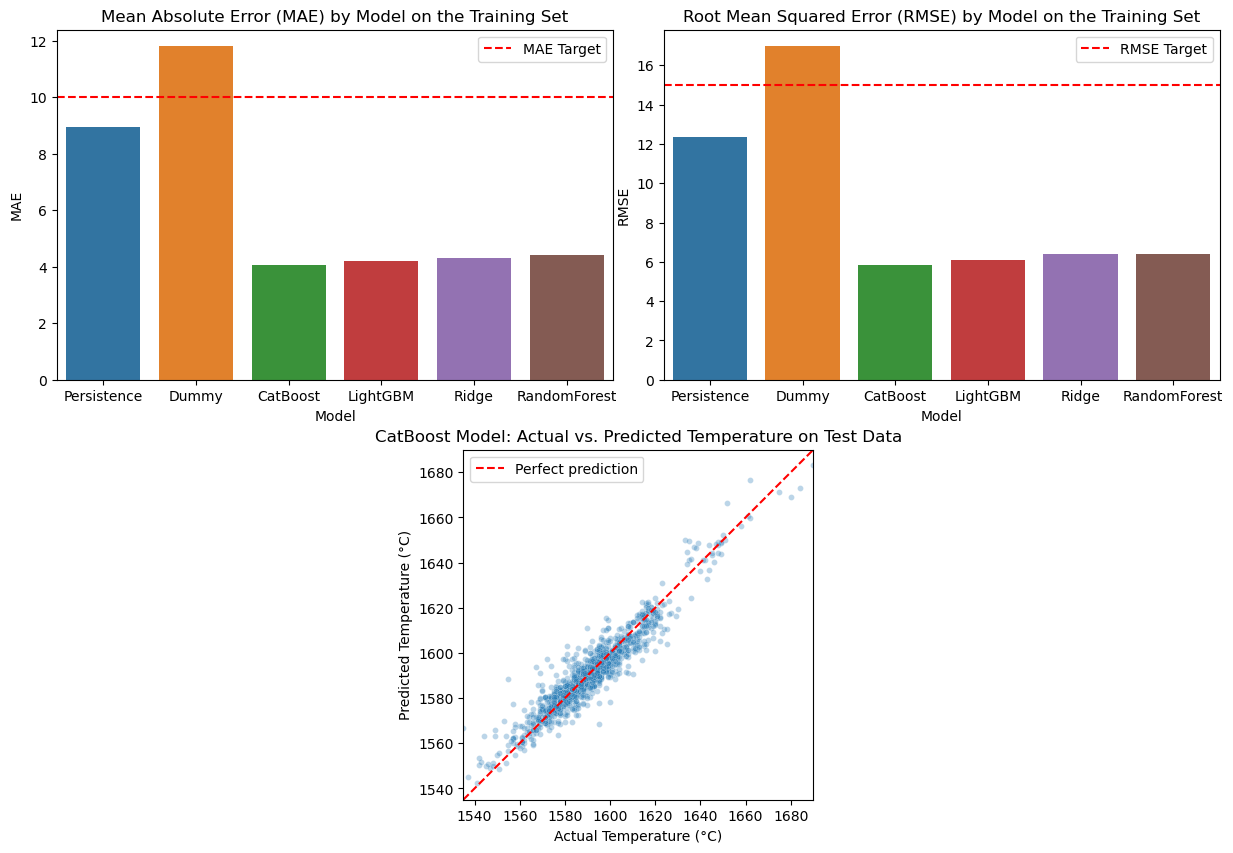

In [5]:
plot_model_diagnostics(test_diagnostics,comparison_df)

The best trained model was CatBoost. After hyperparameter optimization, it achieved an MAE of 4.042°C and an RMSE of 5.824°C on the training data. On the held-out test data, the same model achieved an MAE of 3.927°C and an RMSE of 5.584°C. The model performed well below our KPI thresholds of 10°C for MAE and 15°C for RMSE. For the KPI measuring improvement over the baseline, the model also performed well, with a 54.88% improvement on the training data and 59.25% on the test data. These figures were calculated from the MAE values of the model and the persistence baseline, whose test-set MAE and RMSE were 9.64°C and 13.23°C, respectively. The best hyperparameters found were 900 iterations, `depth = 4`, and `learning_rate = 0.05`.

Nevertheless, there were limitations. Our model produces some very large errors for certain predictions, although these are relatively uncommon. Some larger errors were observed in longer intervals, but those intervals are less common in the data, which limits our ability to assess this relationship. Errors are also more tightly concentrated for intervals with heating cycles than for intervals with material additions but no heating cycles. The latter intervals are also less common.

As an initial step toward operational validation, we suggest prioritizing intervals with heating cycles lasting no more than 30 minutes, since these conditions are more heavily represented in the data. This selection does not guarantee reliable predictions and should be accompanied by direct temperature measurements to evaluate performance.

Finally, the model's performance must be assessed by domain specialists to understand the risks and limitations involved in using such a virtual sensor as a potential replacement for manual measurements. Metallurgical constraints must be defined explicitly before it is possible to determine whether the model's performance is adequate.

## 5. Business Impact

Steelproof's main business objective is to reduce the costs of secondary refining, particularly those related to electricity consumption. Although we developed a model with good predictive performance, we still cannot estimate how much the company could save by using it. Our model estimates temperatures; it does not calculate electricity consumption directly or determine the optimal heating conditions.

1. **Virtual Sensor:**

   One possible application of the virtual sensor would be to reduce the need for some direct temperature measurements. This could lower measurement-related costs and, depending on how measurements are performed, reduce the time spent on the process. We would need to know the cost and frequency of these measurements and determine in which situations predictions could safely replace them without compromising steel quality or operational safety. As established in our initial project plan, the dataset contains 3,216 secondary refining batches and a total of 15,907 temperature measurements, averaging 4.95 measurements per batch. If the model could be used as a virtual sensor to reduce this average by one measurement per batch, that would mean 3,216 fewer measurements, or a 20% reduction in all measurements taken during the period analyzed. In that scenario, once Steelproof provided the time and cost of each measurement, we could calculate the process hours and the amount of money potentially saved on measurements.

2. **Future Direction — Heating Cycle Optimization:**

   Another possible application would be to use temperature estimates to support heating decisions. With more frequent information about steel temperature, operators might eventually identify situations in which another heating cycle is unnecessary. This could potentially reduce electricity consumption, but our experiment does not allow us to conclude that such savings would actually occur.

To evaluate the potential benefits in concrete terms, we would need additional information on electricity consumption, measurement costs, the characteristics of different steel grades, and the operational decisions made during refining. We would also need to account for the implementation and maintenance costs of the virtual sensor itself.

Therefore, the economic impact identified in this project is still qualitative. We demonstrated that temperature estimates can be obtained with substantially lower average error than a persistence baseline, but turning that predictive capability into savings for Steelproof depends on operational testing and an evaluation of the associated costs and benefits.

## 6. Conclusions and Recommendations

The project demonstrated that the available operational records can be used to develop a predictive model for steel temperature during secondary refining. CatBoost performed best among the evaluated models, achieving a test-set MAE of 3.93°C and a 59.25% reduction in error compared with the persistence baseline. All performance thresholds established for the project were met.

We consider these results satisfactory for an initial experimental version of the virtual sensor. However, good performance on historical data does not mean the model is ready to replace direct temperature measurements. Besides not knowing Steelproof's operational tolerances, the model was developed using intervals bounded by actual temperature measurements, and its performance at arbitrary points in time has not yet been validated.

Our main recommendation is to conduct an operational validation phase in which the model runs alongside direct temperature measurements without initially replacing them. We could begin with intervals containing heating cycles and lasting no more than 30 minutes, since these conditions are better represented in the dataset. This evaluation would allow us to identify errors under real operating conditions and work with the operations and quality-control teams to determine acceptable limits for each process.

We also recommend improving data collection, particularly for gas purging, the characteristics of different steel grades, and information about electrical power and energy consumption. These data could support future versions of the model and enable a more complete investigation of its potential to save energy.

Only after this validation could we decide in which situations the virtual sensor might be used as an operational reference and whether its deployment would deliver enough economic benefit to justify the associated costs and risks.

## 7. Technical Details

We used imputation with RandomForestRegressor because we were working with scikit-learn version 0.24.1, in which RandomForestRegressor cannot handle missing values.